<a href="https://colab.research.google.com/github/anderafryanto-dotcom/Spirulina-based-Microcapsules-Control-Release/blob/main/Note_4_Final_Feed_Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES, LOAD MODEL & DATA, AND EXPORT COLORIZED CORRELATION
# ============================================================

import os
import re
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from openpyxl.formatting.rule import ColorScaleRule

from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import shap

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

# Output directory
OUTPUT_DIR = "Ridge_SHAP_Analysis"
FIGURE_DIR = os.path.join(OUTPUT_DIR, "Figures")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

# ------------------------------------------------------------
# LOAD THE FINAL TUNED RIDGE MODEL
# ------------------------------------------------------------

MODEL_PATH = "Release_Final_Ridge.pkl"
final_ridge = joblib.load(MODEL_PATH)

# ------------------------------------------------------------
# LOAD THE EXISTING TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train = joblib.load("X_train_release.pkl")
X_test = joblib.load("X_test_release.pkl")

y_train = joblib.load("y_train_release.pkl")
y_test = joblib.load("y_test_release.pkl")

# Convert targets to 1D arrays for evaluation
y_train_array = np.asarray(y_train).reshape(-1)
y_test_array = np.asarray(y_test).reshape(-1)

# Ensure feature matrices are DataFrames
if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train)

if not isinstance(X_test, pd.DataFrame):
    X_test = pd.DataFrame(X_test)

# Remove non-feature columns like Sample_ID if present
if "Sample_ID" in X_train.columns:
    X_train = X_train.drop(columns=["Sample_ID"])
if "Sample_ID" in X_test.columns:
    X_test = X_test.drop(columns=["Sample_ID"])

# Ensure consistent feature ordering
if list(X_train.columns) != list(X_test.columns):
    raise ValueError(
        "X_train and X_test must contain identical "
        "feature names in the same order."
    )

# Check missing values
if X_train.isna().any().any():
    raise ValueError("Missing values detected in X_train.")

if X_test.isna().any().any():
    raise ValueError("Missing values detected in X_test.")

# Check dimensions
assert len(X_train) == len(y_train_array)
assert len(X_test) == len(y_test_array)

print("Ridge model loaded successfully.")
print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

# ------------------------------------------------------------
# BASIC MODEL VALIDATION
# ------------------------------------------------------------

y_pred = np.asarray(final_ridge.predict(X_test)).reshape(-1)

test_r2 = r2_score(y_test_array, y_pred)
test_rmse = np.sqrt(
    mean_squared_error(y_test_array, y_pred)
)
test_mae = mean_absolute_error(y_test_array, y_pred)

print("\nFINAL RIDGE PERFORMANCE")
print(f"Test R2   : {test_r2:.6f}")
print(f"Test RMSE : {test_rmse:.6g}")
print(f"Test MAE  : {test_mae:.6g}")

# Save evaluation metrics
performance_df = pd.DataFrame({
    "Metric": ["R2", "RMSE", "MAE"],
    "Test_Value": [test_r2, test_rmse, test_mae]
})

performance_df.to_excel(
    os.path.join(OUTPUT_DIR, "Ridge_Test_Performance.xlsx"),
    index=False
)

# ------------------------------------------------------------
# EXPORT CORRELATION MATRIX WITH EXCEL COLORMAP
# ------------------------------------------------------------

try:
    # Get top 20 features from global SHAP if available in global scope
    top20_feats = [
        "A_633", "A_623", "A_631", "A_632", "A_630",
        "A_636", "A_634", "A_624", "A_637", "A_622",
        "A_635", "A_621", "A_638", "A_629", "A_625",
        "A_628", "A_655", "A_627", "A_609", "A_699"
    ]

    # Ensure we only use columns that exist
    valid_cols = [col for col in top20_feats if col in X_train.columns]
    corr_df = X_train[valid_cols].corr(method="pearson")

    file_path = os.path.join(OUTPUT_DIR, "Ridge_SHAP_Top20_Correlation_Colorized.xlsx")

    # Save to Excel
    corr_df.to_excel(file_path)

    # Apply Colormap Style Formatting using openpyxl (Blue - White - Red style)
    wb = openpyxl.load_workbook(file_path)
    ws = wb.active

    # Color scale rule from -1 (Blue), 0 (White), to 1 (Red)
    color_scale = ColorScaleRule(
        start_type='num', start_value=-1, start_color='99B2D8', # Soft Blue
        mid_type='num', mid_value=0, mid_color='FFFFFF',        # White
        end_type='num', end_value=1, end_color='E57C7C'         # Soft Red
    )

    # Determine the matrix grid size to format (excluding headers)
    max_row = ws.max_row
    max_col = ws.max_column

    # Apply rule starting from column 2 and row 2
    cell_range = f"{openpyxl.utils.get_column_letter(2)}2:{openpyxl.utils.get_column_letter(max_col)}{max_row}"
    ws.conditional_formatting.add(cell_range, color_scale)

    wb.save(file_path)
    print(f"\nSaved Colorized Correlation Matrix to: {file_path}")
except Exception as e:
    print(f"\nCould not colorize Excel: {e}")

Ridge model loaded successfully.
Training samples: 120
Test samples: 30
Number of features: 605

FINAL RIDGE PERFORMANCE
Test R2   : 0.976504
Test RMSE : 9.08194e-05
Test MAE  : 7.57165e-05

Saved Colorized Correlation Matrix to: Ridge_SHAP_Analysis/Ridge_SHAP_Top20_Correlation_Colorized.xlsx


In [ ]:
# ============================================================
# 2. SHAP ANALYSIS (RIDGE REGRESSION)
# ============================================================

# Menggunakan .predict dari pipeline agar dapat dipanggil (callable) oleh SHAP Explainer
explainer = shap.Explainer(final_ridge.predict, X_train)

# Menghitung SHAP values pada data uji (X_test) dengan max_evals yang memadai
# Karena fitur = 605, minimal max_evals adalah 2 * 605 + 1 = 1211
shap_explanation = explainer(X_test, max_evals=1500)

# Mengambil matriks nilai SHAP
shap_values = np.asarray(shap_explanation.values)

# Jika output berupa 3 dimensi (single-output dengan dimensi ekstra), ubah ke 2 dimensi
if shap_values.ndim == 3:
    if shap_values.shape[-1] != 1:
        raise ValueError(
            "This code expects a single-output regression model."
        )
    shap_values = shap_values[:, :, 0]

if shap_values.shape != X_test.shape:
    raise ValueError(
        f"Unexpected SHAP shape: {shap_values.shape}; "
        f"expected {X_test.shape}."
    )

print("SHAP analysis completed for Ridge model.")
print("SHAP matrix shape:", shap_values.shape)

# ------------------------------------------------------------
# GLOBAL SHAP IMPORTANCE
# ------------------------------------------------------------

mean_abs_shap = np.mean(
    np.abs(shap_values),
    axis=0
)

mean_shap = np.mean(
    shap_values,
    axis=0
)

shap_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": mean_abs_shap,
    "Mean_SHAP": mean_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance_df["Rank"] = (
    np.arange(1, len(shap_importance_df) + 1)
)

shap_importance_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Ridge_SHAP_Global_Importance.xlsx"
    ),
    index=False
)

display(shap_importance_df.head(20))

PermutationExplainer explainer: 31it [01:07,  2.59s/it]

SHAP analysis completed for Ridge model.
SHAP matrix shape: (30, 605)


,Feature,Mean_Absolute_SHAP,Mean_SHAP,Rank
0,Medium,0.000008,-4.849525e-07,1
1,A_615,0.000007,1.481929e-06,2
2,A_619,0.000007,1.242252e-06,3
3,A_618,0.000007,1.226358e-06,4
4,A_620,0.000007,1.185900e-06,5
5,A_617,0.000007,1.234304e-06,6
6,A_621,0.000007,1.115001e-06,7
7,A_622,0.000007,1.021851e-06,8
8,A_616,0.000007,1.355317e-06,9
9,A_623,0.000007,9.434014e-07,10


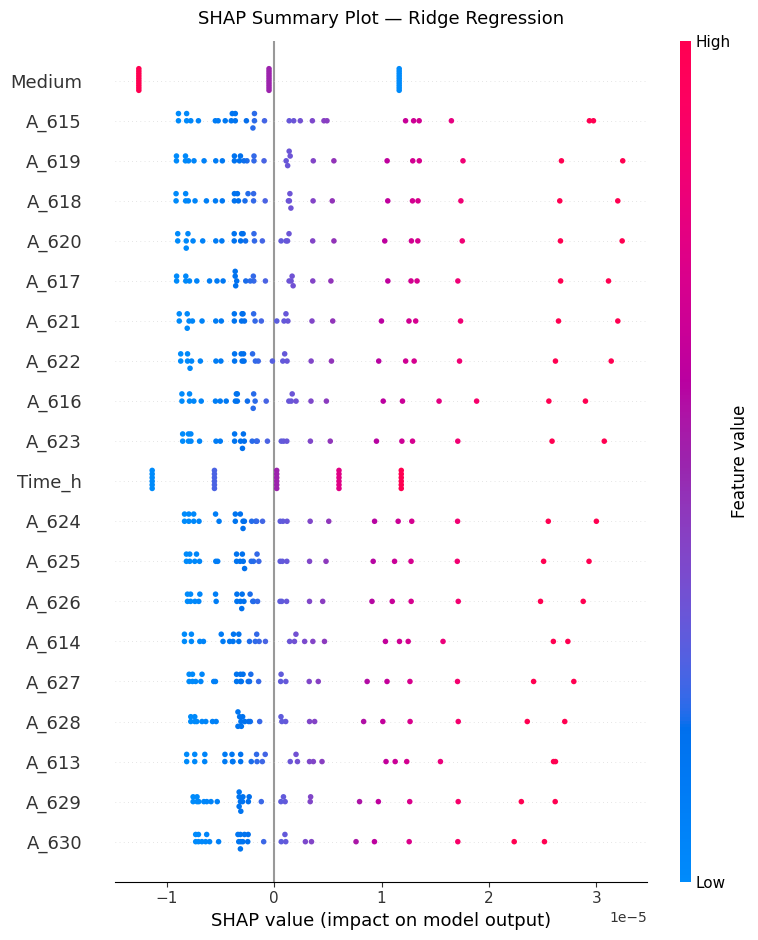

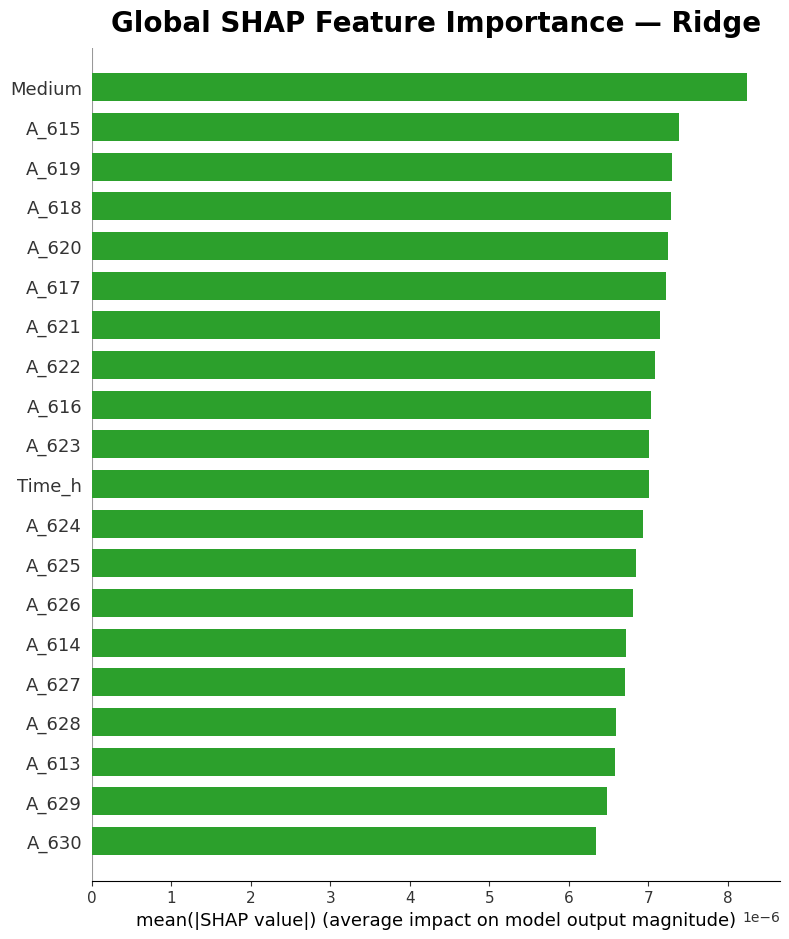

In [ ]:
# ============================================================
# 3. SHAP SUMMARY PLOTS
# ============================================================

# Beeswarm plot
plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_test,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary Plot — Ridge Regression",
    fontsize=13,
    pad=12
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Summary_Beeswarm.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Summary_Beeswarm.svg"
    ),
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# SHAP GLOBAL IMPORTANCE BAR PLOT
# ------------------------------------------------------------

plt.figure(figsize=(7, 8))

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    max_display=20,
    color="#2ca02c",
    show=False
)

plt.title(
    "Global SHAP Feature Importance — Ridge",
    fontsize=20,
    fontweight="bold",
    pad=12
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Global_Bar.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Global_Bar.svg"
    ),
    bbox_inches="tight"
)

plt.show()

Number of spectral features: 601
Wavelength range: 200.0 to 800.0 nm


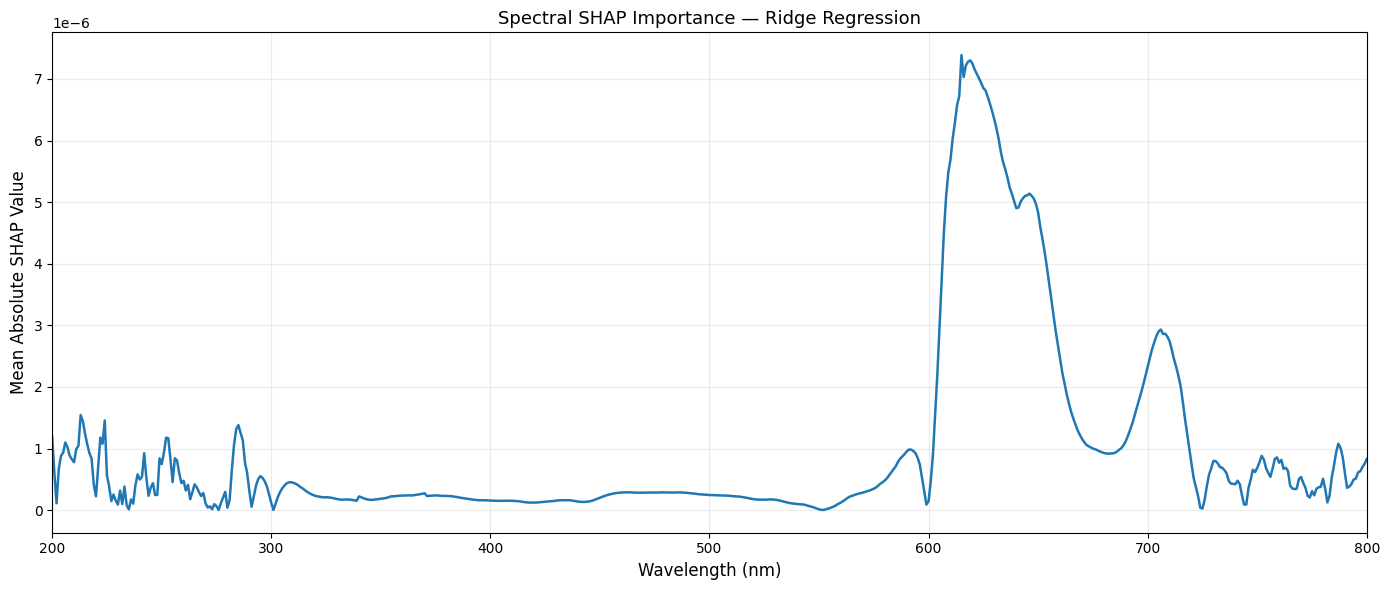

In [ ]:
# ============================================================
# 4. IDENTIFY WAVELENGTH FEATURES
# ============================================================

def extract_wavelength(feature_name):
    """
    Extract wavelength from names such as A_615 or A_652.
    Return NaN for non-spectral features.
    """
    match = re.fullmatch(
        r"A_(\d+(?:\.\d+)?)",
        str(feature_name)
    )

    if match:
        return float(match.group(1))

    return np.nan


wavelength_df = shap_importance_df.copy()

wavelength_df["Wavelength_nm"] = (
    wavelength_df["Feature"]
    .apply(extract_wavelength)
)

spectral_shap_df = wavelength_df.dropna(
    subset=["Wavelength_nm"]
).copy()

spectral_shap_df = spectral_shap_df.sort_values(
    "Wavelength_nm"
).reset_index(drop=True)

if spectral_shap_df.empty:
    raise ValueError(
        "No wavelength columns matching A_<wavelength> "
        "were detected. Check the feature names."
    )

print(
    "Number of spectral features:",
    len(spectral_shap_df)
)

print(
    "Wavelength range:",
    spectral_shap_df["Wavelength_nm"].min(),
    "to",
    spectral_shap_df["Wavelength_nm"].max(),
    "nm"
)

spectral_shap_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Ridge_SHAP_Spectral_Importance.xlsx"
    ),
    index=False
)


# ------------------------------------------------------------
# SPECTRAL SHAP PROFILE
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    spectral_shap_df["Wavelength_nm"],
    spectral_shap_df["Mean_Absolute_SHAP"],
    linewidth=1.8
)

plt.xlabel("Wavelength (nm)", fontsize=12)

plt.ylabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.title(
    "Spectral SHAP Importance — Ridge Regression",
    fontsize=13
)

plt.xlim(
    spectral_shap_df["Wavelength_nm"].min(),
    spectral_shap_df["Wavelength_nm"].max()
)

plt.grid(
    True,
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Spectral_Profile.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Spectral_Profile.svg"
    ),
    bbox_inches="tight"
)

plt.show()

,Rank,Feature,Mean_Absolute_SHAP,Mean_SHAP,Wavelength_nm
0,1,A_615,0.000007,1.481929e-06,615.0
1,2,A_619,0.000007,1.242252e-06,619.0
2,3,A_618,0.000007,1.226358e-06,618.0
3,4,A_620,0.000007,1.185900e-06,620.0
4,5,A_617,0.000007,1.234304e-06,617.0
5,6,A_621,0.000007,1.115001e-06,621.0
6,7,A_622,0.000007,1.021851e-06,622.0
7,8,A_616,0.000007,1.355317e-06,616.0
8,9,A_623,0.000007,9.434014e-07,623.0
9,10,A_624,0.000007,8.849837e-07,624.0


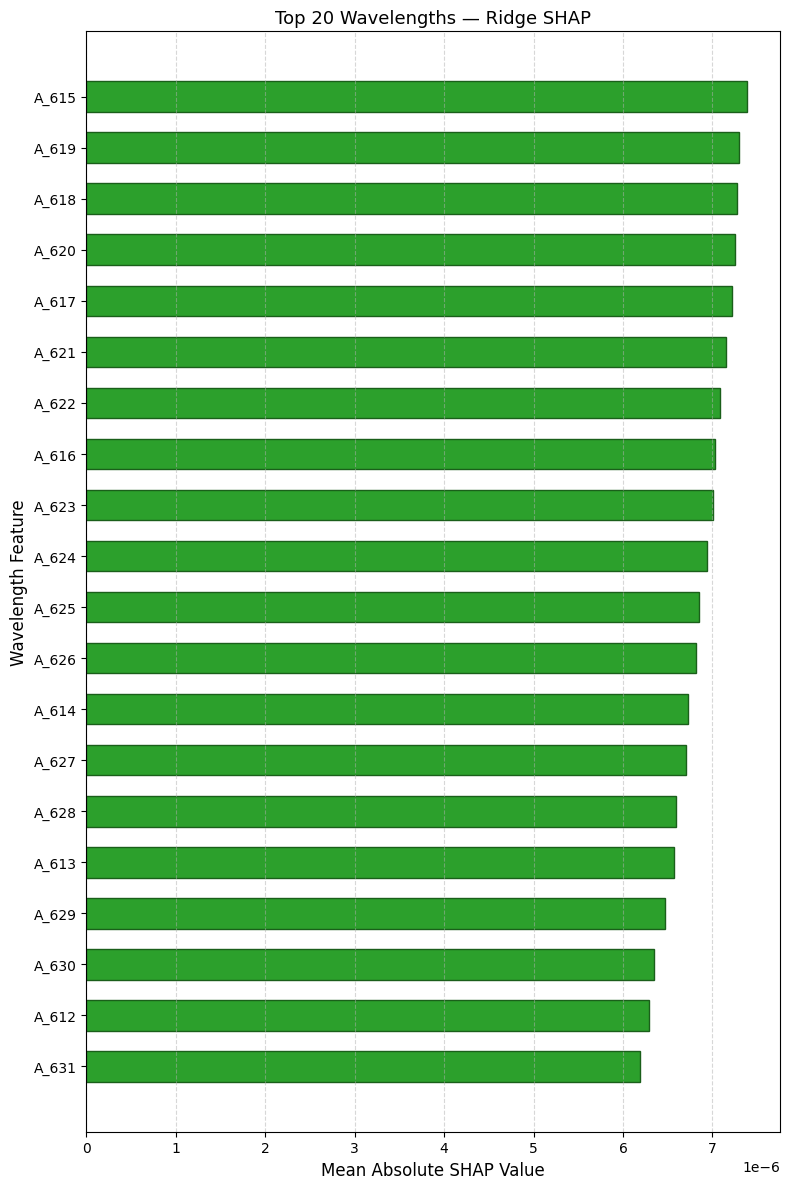

In [ ]:
# ============================================================
# 5. TOP 20 IMPORTANT WAVELENGTHS
# ============================================================

top20_wavelengths = (
    spectral_shap_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .head(20)
    .reset_index(drop=True)
)

# Hapus kolom 'Rank' bawaan terlebih dahulu jika ingin membuat urutan baru
if "Rank" in top20_wavelengths.columns:
    top20_wavelengths = top20_wavelengths.drop(columns=["Rank"])

top20_wavelengths.insert(
    0,
    "Rank",
    np.arange(1, len(top20_wavelengths) + 1)
)

display(top20_wavelengths)

top20_wavelengths.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Ridge_SHAP_Top20_Wavelengths.xlsx"
    ),
    index=False
)


# ------------------------------------------------------------
# PLOT TOP 20 WAVELENGTHS (REVERTED TO PREVIOUS FONT SIZES)
# ------------------------------------------------------------

plot_top20 = top20_wavelengths.sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

plt.figure(figsize=(8, 12))

# Menggunakan warna hijau estetis
plt.barh(
    plot_top20["Feature"],
    plot_top20["Mean_Absolute_SHAP"],
    color="#2ca02c",
    edgecolor="#1a5f1a",
    height=0.6
)

# Mengembalikan ukuran font ke setelan awal (fontsize=12 & 13 tanpa bold/labelpad berlebih)
plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Wavelength Feature",
    fontsize=12
)

plt.title(
    "Top 20 Wavelengths — Ridge SHAP",
    fontsize=13
)

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Top20_Wavelengths.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Top20_Wavelengths.svg"
    ),
    bbox_inches="tight"
)

plt.show()

,Feature,Permutation_Importance_Mean,Permutation_Importance_SD,Rank
0,Medium,3.003365e-06,1.680682e-06,1
1,Time_h,5.962573e-07,1.404708e-06,2
2,A_591,4.164783e-07,2.629894e-07,3
3,A_592,4.135680e-07,2.632079e-07,4
4,A_590,4.006760e-07,2.533816e-07,5
5,A_593,3.981295e-07,2.575828e-07,6
6,A_589,3.791008e-07,2.407145e-07,7
7,A_594,3.773799e-07,2.470795e-07,8
8,A_588,3.553301e-07,2.275509e-07,9
9,A_595,3.400172e-07,2.270981e-07,10


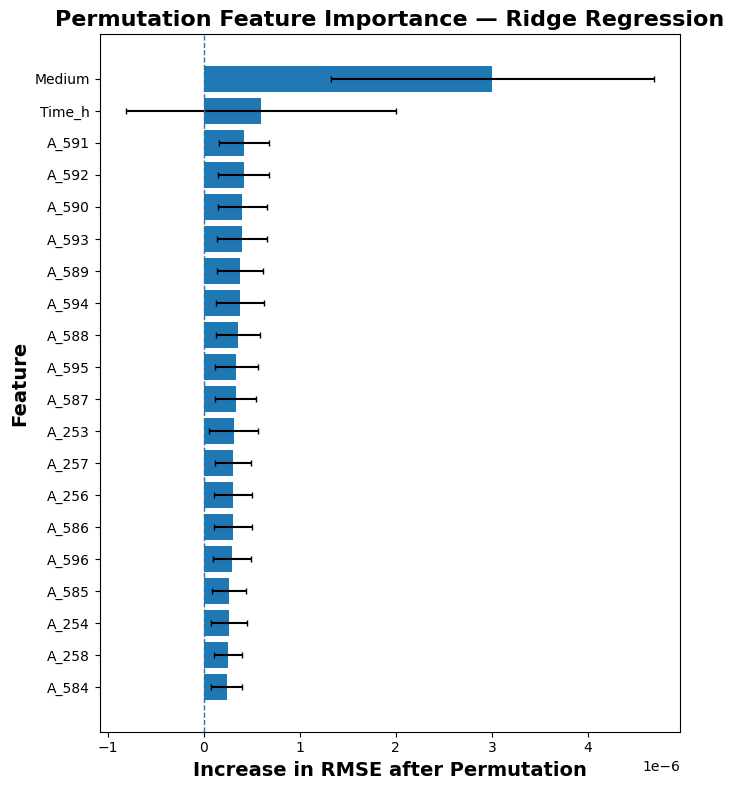

In [ ]:
# ============================================================
# 6. PERMUTATION FEATURE IMPORTANCE
# ============================================================

perm_result = permutation_importance(
    estimator=final_ridge,
    X=X_test,
    y=y_test_array,
    scoring="neg_root_mean_squared_error",
    n_repeats=50,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Permutation_Importance_Mean": (
        perm_result.importances_mean
    ),
    "Permutation_Importance_SD": (
        perm_result.importances_std
    )
})

permutation_df = (
    permutation_df
    .sort_values(
        "Permutation_Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

permutation_df["Rank"] = (
    np.arange(1, len(permutation_df) + 1)
)

permutation_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Ridge_Permutation_Importance.xlsx"
    ),
    index=False
)

display(permutation_df.head(20))


# ------------------------------------------------------------
# PERMUTATION IMPORTANCE PLOT
# ------------------------------------------------------------

top_perm = permutation_df.head(20).sort_values(
    "Permutation_Importance_Mean",
    ascending=True
)

plt.figure(figsize=(7, 8))

plt.barh(
    top_perm["Feature"],
    top_perm["Permutation_Importance_Mean"],
    xerr=top_perm["Permutation_Importance_SD"],
    capsize=2
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Increase in RMSE after Permutation",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "Feature",
    fontsize=14,
    fontweight="bold"
)

plt.title(
    "Permutation Feature Importance — Ridge Regression",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_Permutation_Importance.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_Permutation_Importance.svg"
    ),
    bbox_inches="tight"
)

plt.show()

,Region,Mean_Absolute_SHAP,Sum_Absolute_SHAP,Number_of_Wavelengths,Mean_SHAP_Share_Percent,Sum_SHAP_Share_Percent
0,Phycobiliprotein Region,1.949846e-06,0.000390,200,53.845786,67.252275
3,Scattering Region,8.917972e-07,0.000090,101,24.627334,15.533311
2,Protein Region,5.608534e-07,0.000056,100,15.488191,9.672215
1,Pigment Region,2.186711e-07,0.000044,200,6.038689,7.542198


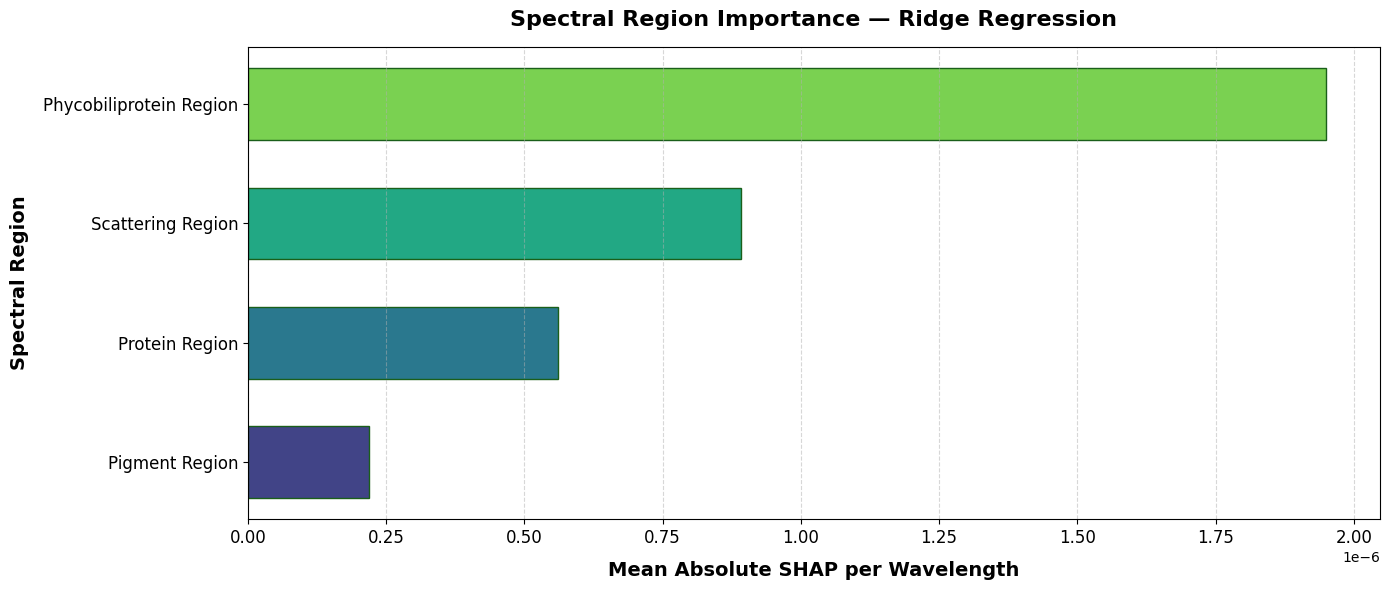

In [ ]:
# ============================================================
# 7. SPECTRAL REGION IMPORTANCE
# ============================================================

region_df = spectral_shap_df.copy()

conditions = [
    (
        (region_df["Wavelength_nm"] >= 200)
        & (region_df["Wavelength_nm"] < 300)
    ),
    (
        (region_df["Wavelength_nm"] >= 300)
        & (region_df["Wavelength_nm"] < 500)
    ),
    (
        (region_df["Wavelength_nm"] >= 500)
        & (region_df["Wavelength_nm"] < 700)
    ),
    (
        (region_df["Wavelength_nm"] >= 700)
        & (region_df["Wavelength_nm"] <= 800)
    )
]

labels = [
    "Protein Region",
    "Pigment Region",
    "Phycobiliprotein Region",
    "Scattering Region"
]

region_df["Region"] = np.select(
    conditions,
    labels,
    default="Other"
)

region_df = region_df[
    region_df["Region"] != "Other"
].copy()

region_importance = (
    region_df
    .groupby("Region")
    .agg(
        Mean_Absolute_SHAP=(
            "Mean_Absolute_SHAP",
            "mean"
        ),
        Sum_Absolute_SHAP=(
            "Mean_Absolute_SHAP",
            "sum"
        ),
        Number_of_Wavelengths=(
            "Feature",
            "count"
        )
    )
    .reset_index()
)

region_importance["Mean_SHAP_Share_Percent"] = (
    region_importance["Mean_Absolute_SHAP"]
    / region_importance["Mean_Absolute_SHAP"].sum()
    * 100
)

region_importance["Sum_SHAP_Share_Percent"] = (
    region_importance["Sum_Absolute_SHAP"]
    / region_importance["Sum_Absolute_SHAP"].sum()
    * 100
)

region_importance = region_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(region_importance)

region_importance.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Ridge_SHAP_Spectral_Region_Importance.xlsx"
    ),
    index=False
)


# ------------------------------------------------------------
# REGION IMPORTANCE PLOT (UPDATED GRADIENT COLORS & FONT SIZES)
# ------------------------------------------------------------

plot_region = region_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

num_bars = len(plot_region)
# Menggunakan colormap 'viridis' yang mentransisikan warna dari Biru (sebelah bawah) ke Hijau-Kuning (sebelah atas)
gradient_colors = plt.cm.viridis(np.linspace(0.2, 0.8, num_bars))

plt.figure(figsize=(14, 6))

plt.barh(
    plot_region["Region"],
    plot_region["Mean_Absolute_SHAP"],
    color=gradient_colors,
    edgecolor="#1a5f1a",
    height=0.6
)

# Memperbesar ukuran label sumbu dan tick labels
plt.xlabel(
    "Mean Absolute SHAP per Wavelength",
    fontsize=14,
    fontweight="bold",
    labelpad=10
)

plt.ylabel(
    "Spectral Region",
    fontsize=14,
    fontweight="bold",
    labelpad=10
)

plt.title(
    "Spectral Region Importance — Ridge Regression",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Spectral_Region_Importance.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Spectral_Region_Importance.svg"
    ),
    bbox_inches="tight"
)

plt.show()

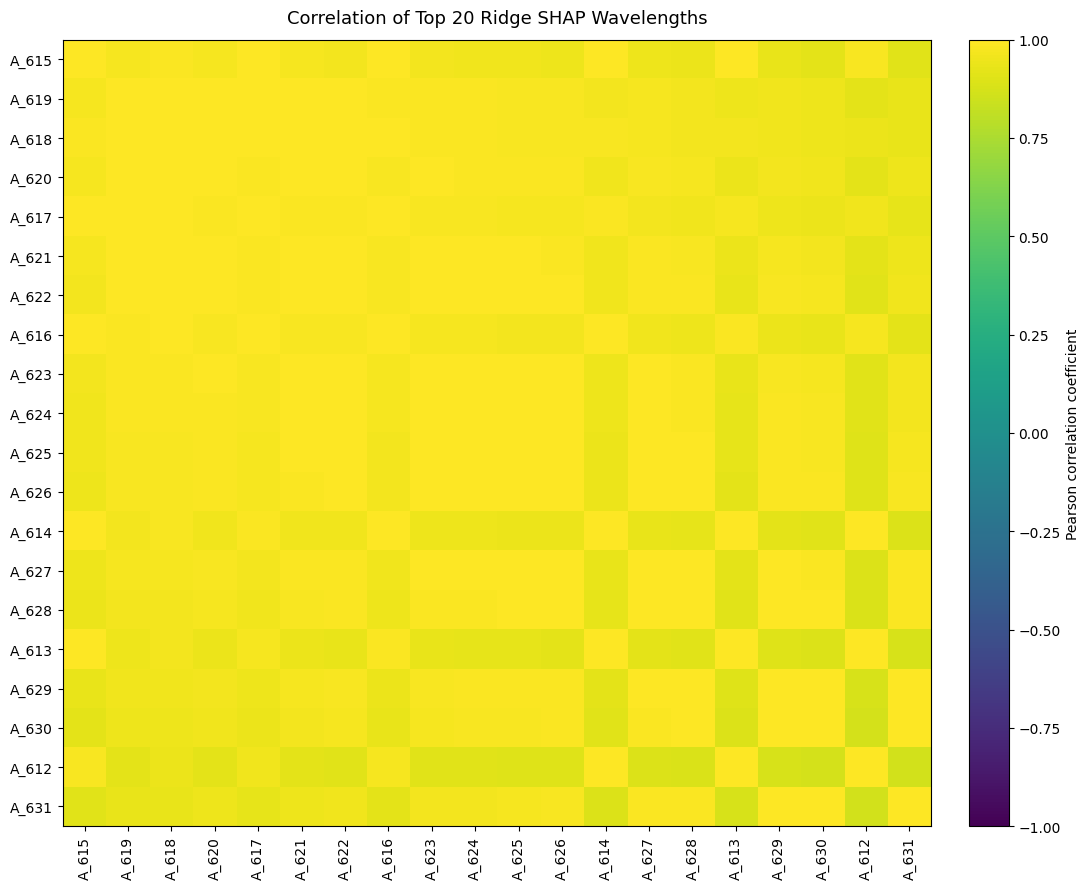

In [ ]:
# ============================================================
# 8. CORRELATION ANALYSIS OF TOP 20 WAVELENGTHS
# ============================================================

top20_features = top20_wavelengths["Feature"].tolist()

X_train_spectral = X_train[
    [
        col for col in X_train.columns
        if not pd.isna(extract_wavelength(col))
    ]
].copy()

X_top20 = X_train_spectral[
    top20_features
]

correlation_matrix = X_top20.corr(
    method="pearson"
)

correlation_matrix.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Ridge_SHAP_Top20_Correlation_Matrix.xlsx"
    )
)


# ------------------------------------------------------------
# CORRELATION HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 9))

im = ax.imshow(
    correlation_matrix.values,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(correlation_matrix.columns))
)

ax.set_yticks(
    np.arange(len(correlation_matrix.index))
)

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=90
)

ax.set_yticklabels(
    correlation_matrix.index
)

ax.set_title(
    "Correlation of Top 20 Ridge SHAP Wavelengths",
    fontsize=13,
    pad=12
)

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Pearson correlation coefficient")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Top20_Correlation_Heatmap.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Ridge_SHAP_Top20_Correlation_Heatmap.svg"
    ),
    bbox_inches="tight"
)

plt.show()

<Figure size 700x500 with 0 Axes>

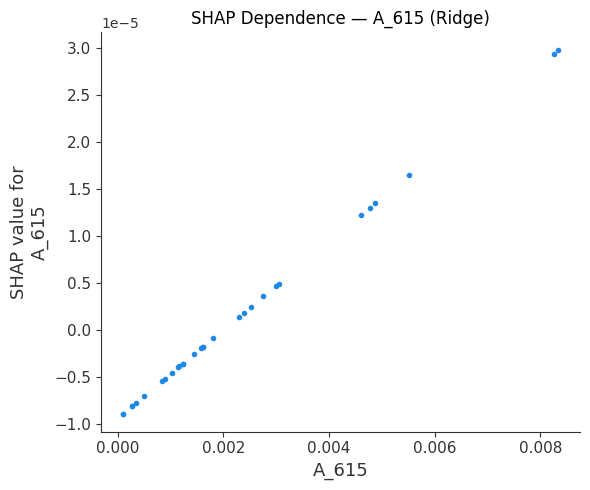

<Figure size 700x500 with 0 Axes>

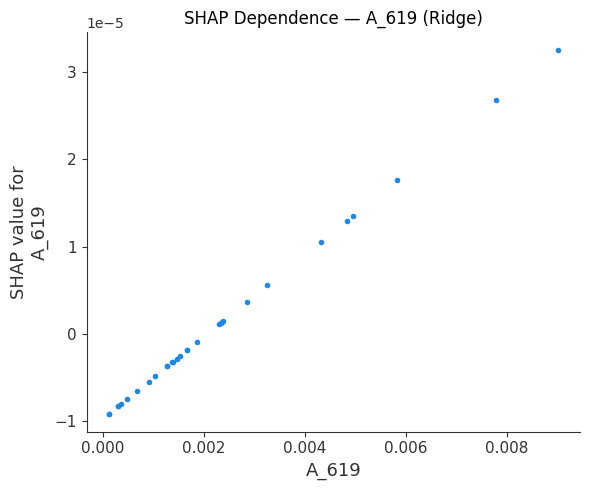

<Figure size 700x500 with 0 Axes>

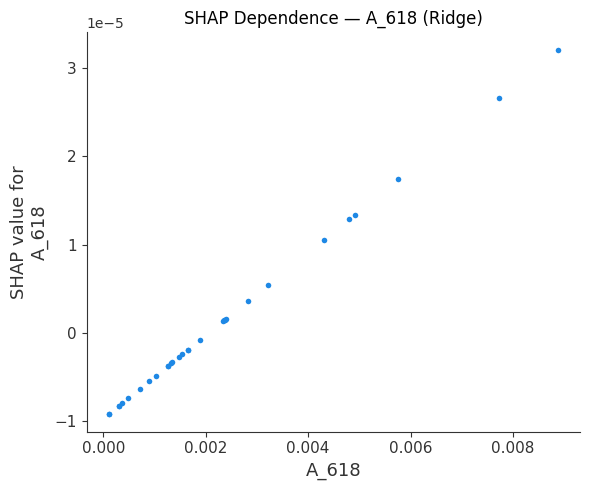

In [ ]:
# ============================================================
# 9. SHAP DEPENDENCE PLOTS
# ============================================================

# Select up to 3 important wavelength features
dependence_features = (
    top20_wavelengths["Feature"]
    .head(3)
    .tolist()
)

for feature in dependence_features:

    plt.figure(figsize=(7, 5))

    shap.dependence_plot(
        feature,
        shap_values,
        X_test,
        interaction_index=None,
        show=False
    )

    plt.title(
        f"SHAP Dependence — {feature} (Ridge)",
        fontsize=12
    )

    plt.tight_layout()

    safe_feature = feature.replace("/", "_")

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            f"Ridge_SHAP_Dependence_{safe_feature}.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            f"Ridge_SHAP_Dependence_{safe_feature}.svg"
        ),
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
# ============================================================
# 10. EXPORT ALL KEY RESULTS TO ONE WORKBOOK
# ============================================================

output_excel = os.path.join(
    OUTPUT_DIR,
    "Ridge_SHAP_Feature_Importance_Complete.xlsx"
)

with pd.ExcelWriter(
    output_excel,
    engine="openpyxl"
) as writer:

    performance_df.to_excel(
        writer,
        sheet_name="Model_Performance",
        index=False
    )

    shap_importance_df.to_excel(
        writer,
        sheet_name="Global_SHAP",
        index=False
    )

    spectral_shap_df.to_excel(
        writer,
        sheet_name="Spectral_SHAP",
        index=False
    )

    top20_wavelengths.to_excel(
        writer,
        sheet_name="Top20_Wavelengths",
        index=False
    )

    permutation_df.to_excel(
        writer,
        sheet_name="Permutation",
        index=False
    )

    region_importance.to_excel(
        writer,
        sheet_name="Spectral_Regions",
        index=False
    )

    correlation_matrix.to_excel(
        writer,
        sheet_name="Top20_Correlation"
    )

print("Analysis completed.")
print("Results saved to:", OUTPUT_DIR)
print("Combined workbook:", output_excel)
print("Figures saved to:", FIGURE_DIR)

Analysis completed.
Results saved to: Ridge_SHAP_Analysis
Combined workbook: Ridge_SHAP_Analysis/Ridge_SHAP_Feature_Importance_Complete.xlsx
Figures saved to: Ridge_SHAP_Analysis/Figures
